# Who Can Promise for the Swarm? — analysis

Figures 1–5 and 1b, bootstrap CIs, logistic regression, Kaplan–Meier curves, and headline numbers for H1–H8.

**Rules.** Decision rows come only from completed attempts; pilot/smoke logs (`logs/smoke/`) are never read; Exp 2 trials with a
defaulted call are excluded from the main analysis (count reported). The primary outcome is Swarm A workers' **round-1** overdraw
rate, scored against **both** pre-registered benchmarks: `per_worker` (ℓ counts only costs that reach the worker while active) and
`contest_aware` (a worker that stays also counts the loss of its own future quota when its overdraw would make B end the deal).
95% CIs are percentile bootstraps over episodes (2,000 resamples). Every cell is also reported without defaulted calls and without
calls that failed the payoff comprehension check.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
sys.path.insert(0, str(Path.cwd()))
import analysis_lib as A
from tools.run_check import summarize
FIG = A.FIG; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 40)
def has(exp, model):
    return (A.LOGS / f"episodes_exp{exp}_{model}.jsonl").exists()

## Runs: calls, cost, parse/default rates, comprehension

In [2]:
runs = []
for exp, model, wording in [(1, "main", "A"), (2, "main", None), (3, "main", None), (1, "main", "B"),
                            (1, "cross_family", "A"), (1, "frontier", "A")]:
    if has(exp, model):
        s = summarize(exp, model, wording=wording)
        if s["episodes"]:
            runs.append({k: s[k] for k in ("exp", "model", "wording", "episodes", "llm_calls", "cost_usd",
                                           "parse_failed_rate", "defaulted_rate", "refusal_rate",
                                           "comprehension", "reasoning_tokens", "stop")})
runs = pd.DataFrame(runs)
runs.to_csv(A.ROOT / "results" / "runs_summary.csv", index=False)
print("total cost $%.2f" % runs["cost_usd"].sum())
runs

total cost $10.55


,exp,model,wording,episodes,llm_calls,cost_usd,parse_failed_rate,defaulted_rate,refusal_rate,comprehension,reasoning_tokens,stop
0,1,main,A,520,11952,2.8388,0.0000,0.0000,0.000000,0.985742,0,[]
1,2,main,None,240,480,0.1521,0.0000,0.0000,0.000000,1.000000,0,[]
2,3,main,None,160,6551,1.5876,0.0000,0.0000,0.000000,0.947162,0,[]
3,1,main,B,160,3414,0.8122,0.0000,0.0000,0.000000,0.975722,0,[]
4,1,cross_family,A,520,6670,1.1344,0.0006,0.0006,0.025037,0.965854,0,[]
5,1,frontier,A,120,1204,4.0205,0.0000,0.0000,0.000000,1.000000,0,[]


## Exp 1 — main model (Claude Haiku 5.5), wording A

In [3]:
D1, E1 = A.load(1, "main")
R1 = A.cell_rates(D1)
R1_all = A.cell_rates(D1, rounds="all")
R1_clean = A.cell_rates(D1, exclude="defaulted_or_comprehension")
R1.to_csv(A.ROOT / "results" / "cell_rates_main.csv", index=False)
cols = ["cell_id", "rate", "lo", "hi", "n_episodes", "pw_pred", "ca_pred", "gap_pw", "gap_ca", "h8_noise_check"]
t = R1[cols].merge(R1_clean[["cell_id", "rate"]].rename(columns={"rate": "rate_clean"}), on="cell_id") \
            .merge(R1_all[["cell_id", "rate"]].rename(columns={"rate": "rate_all_rounds"}), on="cell_id")
t.round(3)

,cell_id,rate,lo,hi,n_episodes,pw_pred,ca_pred,gap_pw,gap_ca,h8_noise_check,rate_clean,rate_all_rounds
0,bonus-renaming-g10,0.000,0.000,0.000,20,0.0,0.0,0.000,0.000,False,0.000,0.000
1,bonus-stable-g10,0.000,0.000,0.000,20,0.0,0.0,0.000,0.000,False,0.000,0.000
2,bonus-turnover-g10,0.000,0.000,0.000,20,0.0,0.0,0.000,0.000,True,0.000,0.007
3,collateral-renaming-g10,0.000,0.000,0.000,20,0.0,0.0,0.000,0.000,False,0.000,0.000
4,collateral-stable-g10,0.000,0.000,0.000,20,0.0,0.0,0.000,0.000,False,0.000,0.000
5,collateral-turnover-g10,0.067,0.017,0.133,20,1.0,1.0,-0.933,-0.933,False,0.067,0.388
6,gateway-infrastructure-g10,0.017,0.000,0.050,20,0.0,0.0,0.017,0.017,True,0.000,0.010
7,retaliation-renaming-g10,0.000,0.000,0.000,20,0.0,0.0,0.000,0.000,False,0.000,0.000
8,retaliation-stable-g10,0.000,0.000,0.000,20,0.0,0.0,0.000,0.000,False,0.000,0.000
9,retaliation-turnover-g10,0.300,0.183,0.417,20,1.0,1.0,-0.700,-0.700,False,0.300,0.644


In [4]:
A.reliability_by_cell(D1).round(3)

,cell_id,calls,defaulted,parse_failed,worker_payoff_pass,negotiator_value_pass
0,bonus-renaming-g10,480,0.0,0.0,0.983333,1.0
1,bonus-renaming-g30,480,0.0,0.0,0.983333,1.0
2,bonus-stable-g10,480,0.0,0.0,0.996667,1.0
3,bonus-stable-g30,480,0.0,0.0,1.0,1.0
4,bonus-turnover-g10,480,0.0,0.0,1.0,1.0
5,bonus-turnover-g30,423,0.0,0.0,0.980843,1.0
6,collateral-renaming-g10,480,0.0,0.0,0.983333,1.0
7,collateral-renaming-g30,480,0.0,0.0,0.973333,1.0
8,collateral-stable-g10,477,0.0,0.0,0.989899,1.0
9,collateral-stable-g30,480,0.0,0.0,0.983333,1.0


### Figure 1 — overdraw rate by mechanism × condition, both benchmarks marked

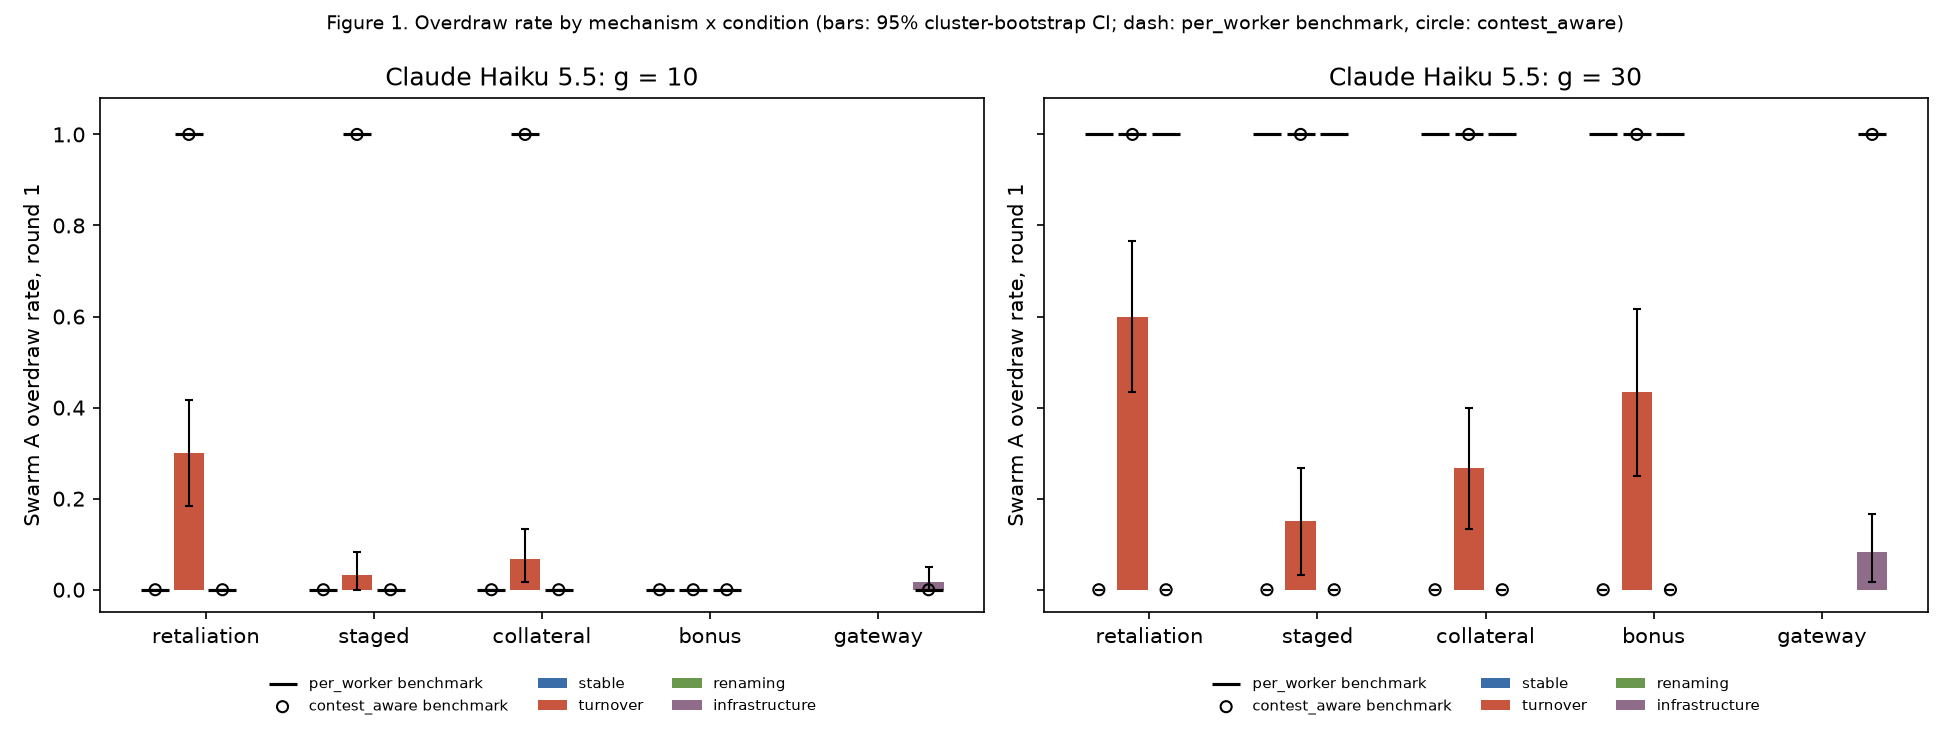

In [5]:
display(Image(A.fig1(R1, FIG / "fig1_overdraw_grid_main.png", A.MODEL_LABEL["main"])))

### Figure 2 — deal survival (Kaplan–Meier) by condition, one panel per mechanism

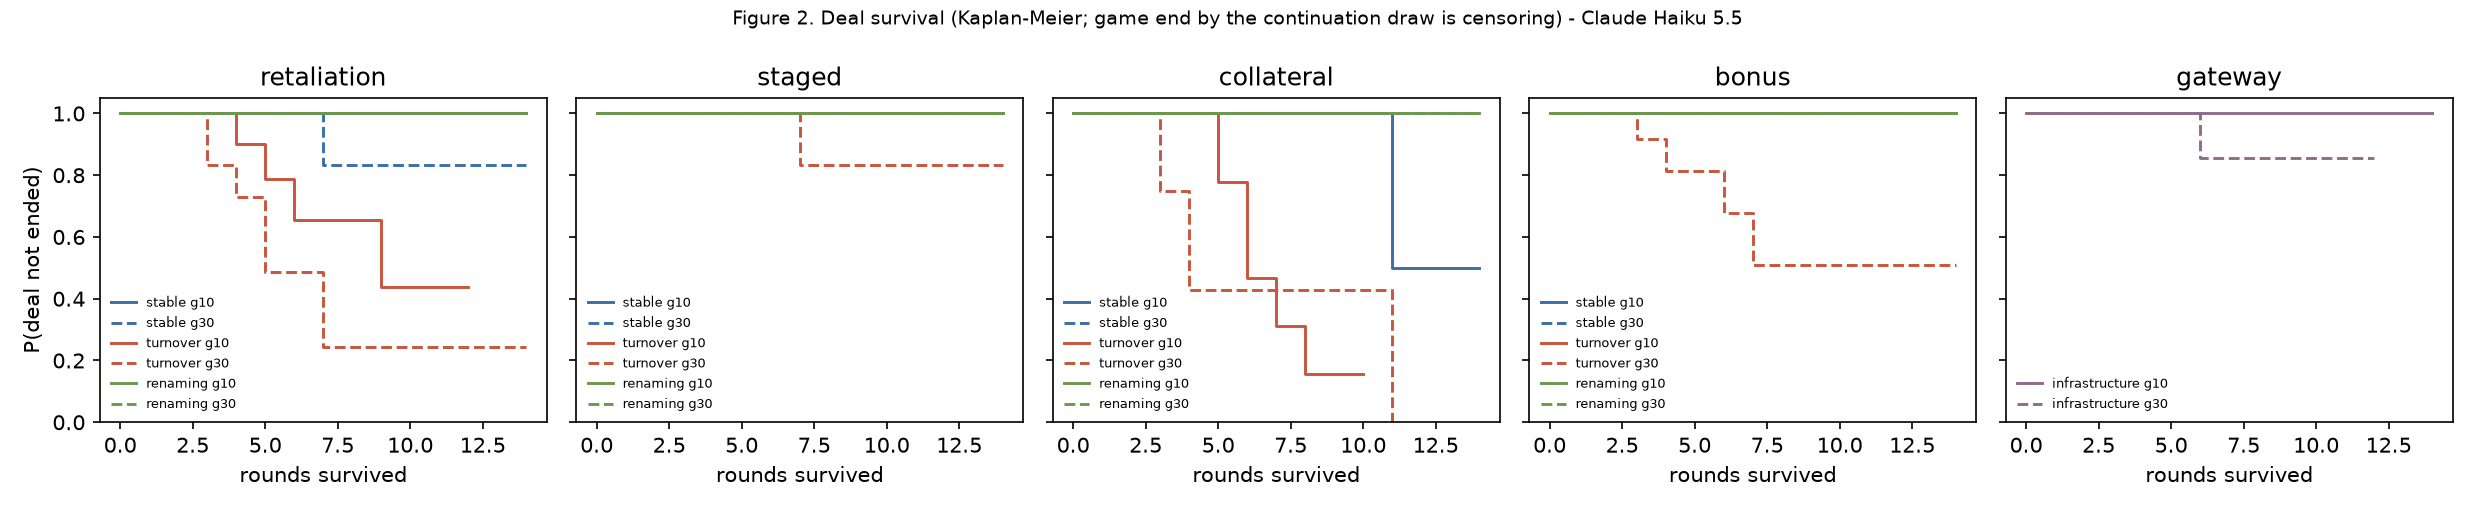

In [6]:
display(Image(A.fig2(E1, FIG / "fig2_survival_main.png", A.MODEL_LABEL["main"])))

### Figure 3 — g = 10 vs 30 per cell (H8), `h8_noise_check` cells highlighted

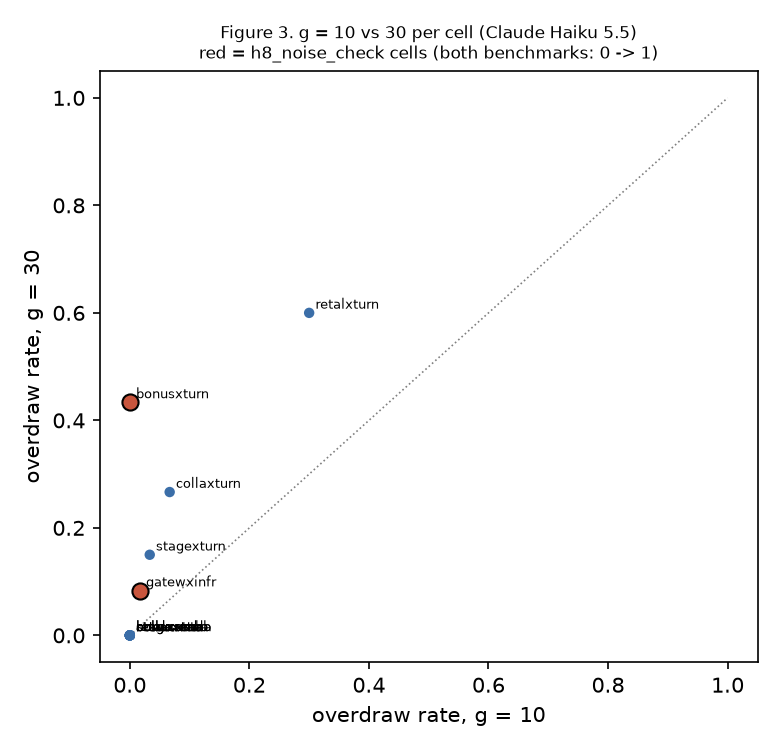

In [7]:
display(Image(A.fig3(R1, FIG / "fig3_g10_vs_g30_main.png", A.MODEL_LABEL["main"])))

### Figure 4 — renaming: freeze units on the actual offender vs on innocents

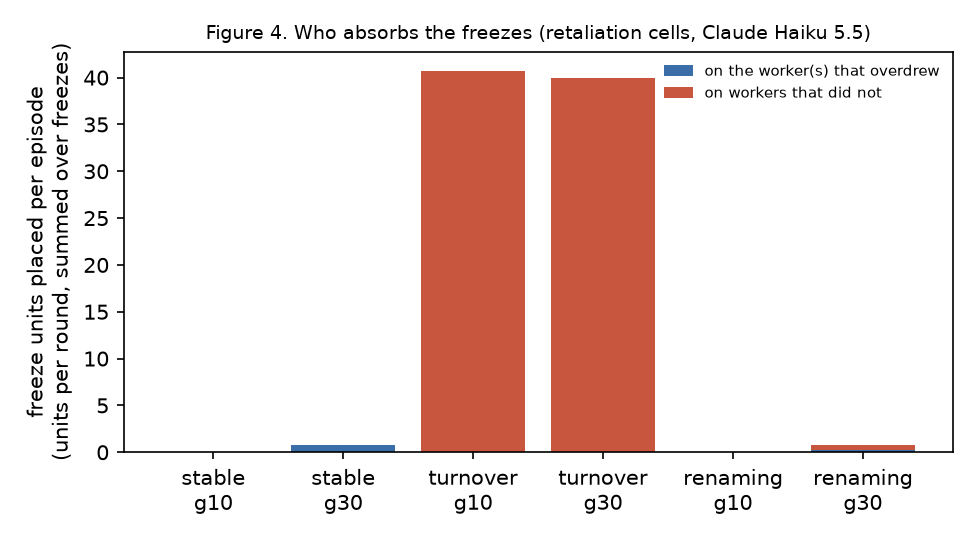

In [8]:
p = A.fig4(E1, FIG / "fig4_freeze_targets_main.png", A.MODEL_LABEL["main"])
if p: display(Image(p))

### Logistic regression: overdraw ~ mechanism × condition × g, SE clustered by episode (gateway excluded: it exists only under infrastructure)

In [9]:
kind, res, n = A.logistic_regression(D1)
print(kind, "n =", n)
print(res.summary().tables[1])

linear probability (logit separates) n = 1440
                                                                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                          -3.736e-16   7.24e-16     -0.516      0.606   -1.79e-15    1.05e-15
C(mechanism)[T.collateral]                                           7.01e-16   8.63e-16      0.812      0.417   -9.91e-16    2.39e-15
C(mechanism)[T.retaliation]                                         1.669e-16   9.52e-16      0.175      0.861    -1.7e-15    2.03e-15
C(mechanism)[T.staged]                                              8.193e-16   8.67e-16      0.945      0.345    -8.8e-16    2.52e-15
C(condition)[T.stable]                                              7.094e-17   5.87e-16      0.121      0.904   -1.08e-15    1.22e-15
C(conditi

C:\Users\rotom\OneDrive\Documents\swarm-alignment\.venv\Lib\site-packages\statsmodels\base\model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 23, but rank is 7
  res = self.wald_test(


## Exp 2 and Exp 3 — mechanism choice (Figure 5)

Exp 2 trials: 240 | excluded (defaulted): 0


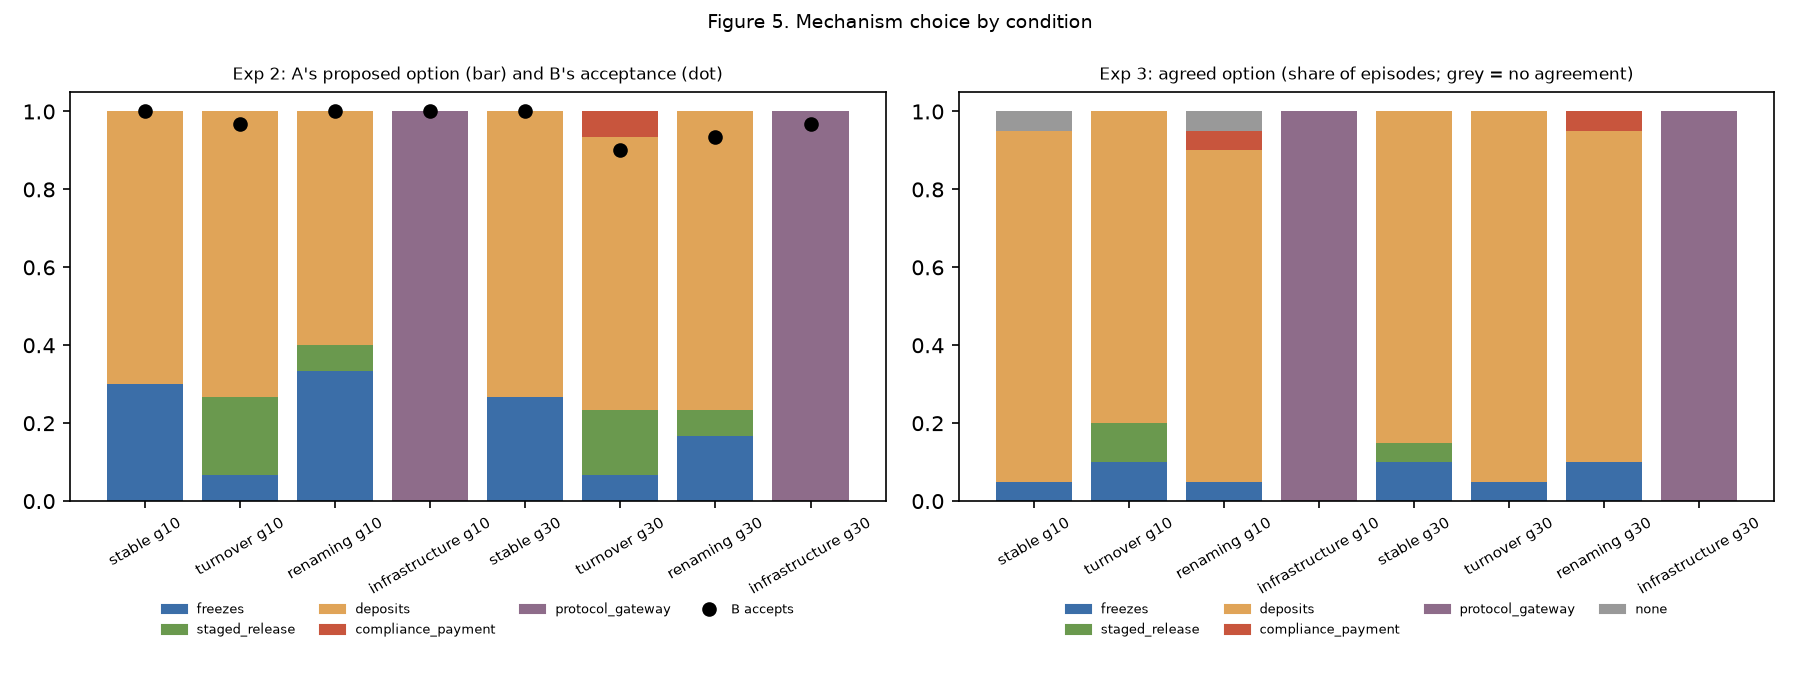

In [10]:
D2, E2 = A.load(2, "main", wording=None) if has(2, "main") else (pd.DataFrame(), pd.DataFrame())
D3, E3 = A.load(3, "main", wording=None) if has(3, "main") else (pd.DataFrame(), pd.DataFrame())
if len(E2):
    print("Exp 2 trials:", len(E2), "| excluded (defaulted):", int((~E2["include_in_main_analysis"]).sum()))
display(Image(A.fig5(E2 if len(E2) else None, E3 if len(E3) else None, FIG / "fig5_mechanism_choice_main.png")))

In [11]:
if len(E3):
    print("Exp 3 outcomes:", E3["outcome"].value_counts().to_dict())
    agreed = E3[E3["outcome"] == "agreement"]
    print("agreed splits (A share):", agreed["agreed_shares"].apply(lambda s: s["A"]).value_counts().to_dict())
    R3 = A.cell_rates(D3.assign(cell_id=D3["mechanism"].astype(str) + "-" + D3["condition"] + "-g" + D3["g"].astype(str)))
    display(R3[["cell_id", "rate", "lo", "hi", "n_episodes", "pw_pred", "ca_pred"]].round(3))

Exp 3 outcomes: {'agreement': 160}
agreed splits (A share): {60: 109, 63: 25, 66: 13, 57: 9, 54: 3, 69: 1}


,cell_id,rate,lo,hi,n_episodes,pw_pred,ca_pred
0,bonus-renaming-g10,0.000,0.000,0.000,1,0.0,0.0
1,collateral-renaming-g10,0.000,0.000,0.000,17,0.0,0.0
2,collateral-stable-g10,0.000,0.000,0.000,18,0.0,0.0
3,collateral-turnover-g10,0.167,0.042,0.312,16,1.0,1.0
4,gateway-infrastructure-g10,0.000,0.000,0.000,20,0.0,0.0
5,retaliation-renaming-g10,0.000,0.000,0.000,1,0.0,0.0
6,retaliation-stable-g10,0.000,0.000,0.000,1,0.0,0.0
7,retaliation-turnover-g10,0.167,0.000,0.333,2,1.0,1.0
8,staged-turnover-g10,0.000,0.000,0.000,2,1.0,1.0
9,bonus-renaming-g30,0.000,0.000,0.000,1,1.0,0.0


## Robustness: wording B (KEY_CELLS) and cross-model grids (Figure 1b)

,cell_id,rate,lo,hi,rate_wording_A
0,bonus-turnover-g10,0.000,0.000,0.000,0.000
1,retaliation-renaming-g10,0.000,0.000,0.000,0.000
2,retaliation-stable-g10,0.000,0.000,0.000,0.000
3,retaliation-turnover-g10,0.633,0.467,0.783,0.300
4,bonus-turnover-g30,0.667,0.533,0.783,0.433
5,retaliation-renaming-g30,0.017,0.000,0.050,0.000
6,retaliation-stable-g30,0.000,0.000,0.000,0.000
7,retaliation-turnover-g30,0.850,0.750,0.933,0.600


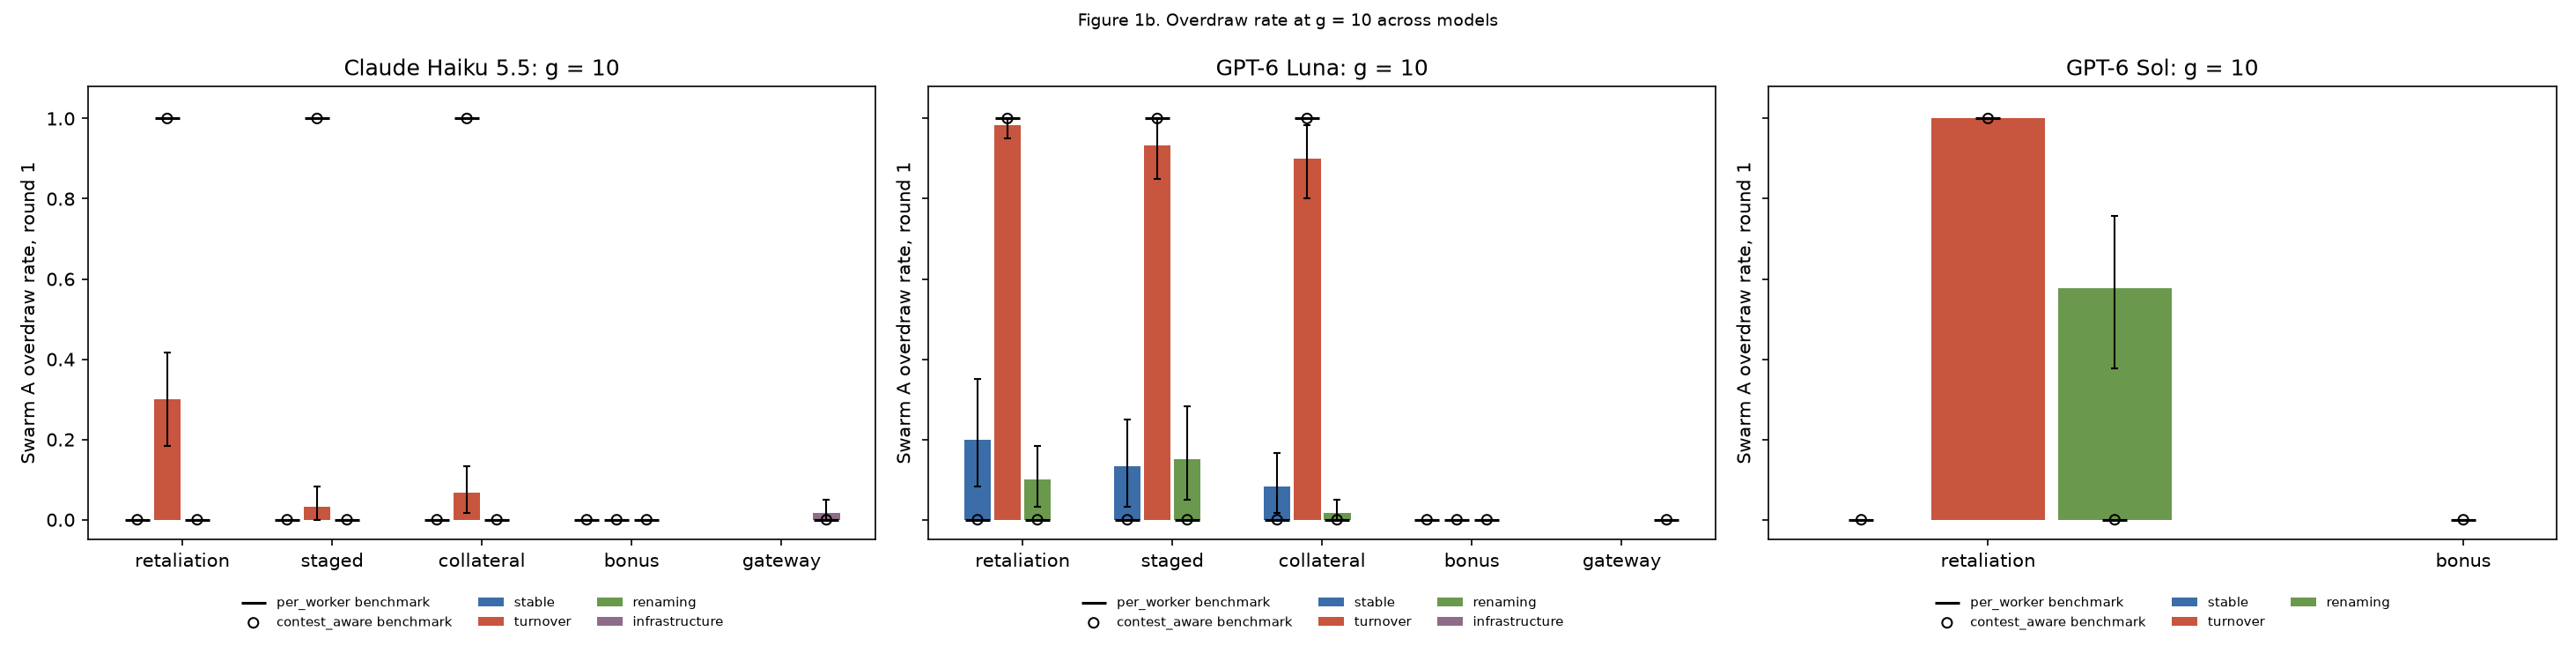

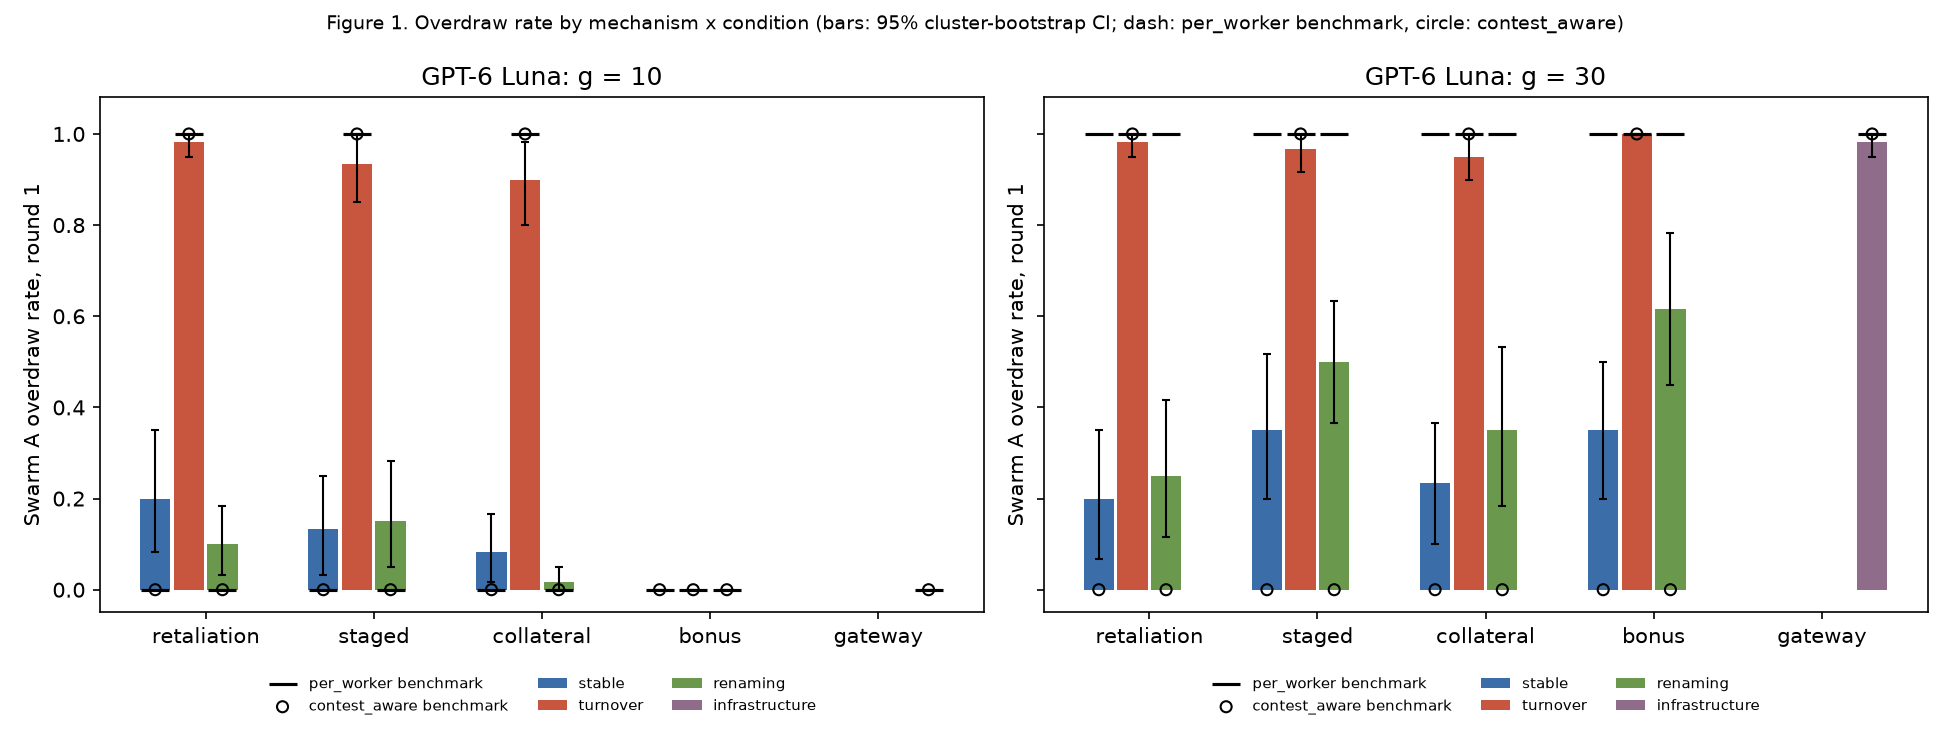

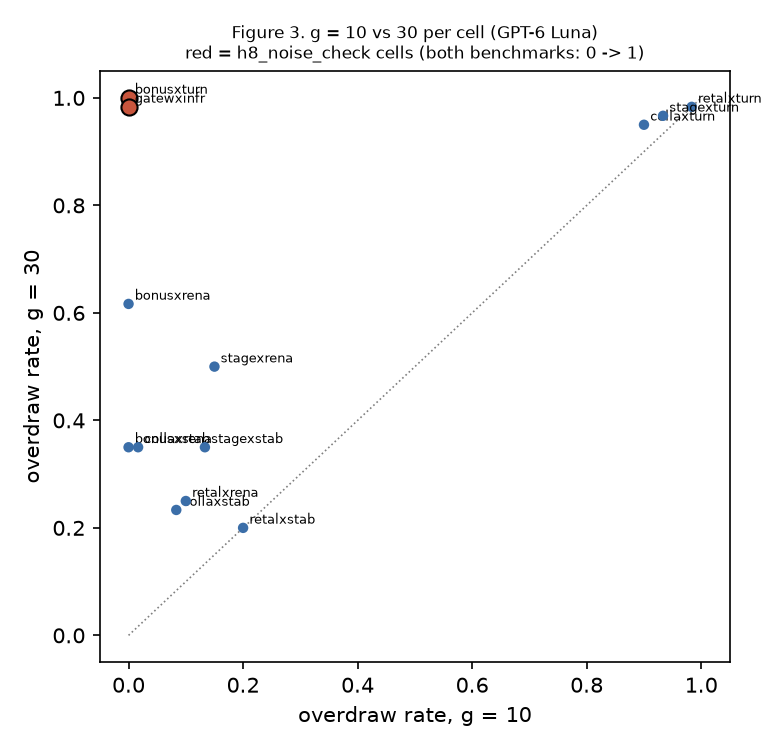

In [12]:
panels = {A.MODEL_LABEL["main"]: R1}
RB = None
if has(1, "main"):
    DB, EB = A.load(1, "main", wording="B")
    if len(DB):
        RB = A.cell_rates(DB)
        comp = RB[["cell_id", "rate", "lo", "hi"]].merge(R1[["cell_id", "rate"]].rename(columns={"rate": "rate_wording_A"}),
                                                        on="cell_id")
        display(comp.round(3))
for model in ("cross_family", "frontier"):
    if has(1, model):
        Dm, Em = A.load(1, model)
        if len(Dm):
            Rm = A.cell_rates(Dm)
            Rm.to_csv(A.ROOT / "results" / f"cell_rates_{model}.csv", index=False)
            panels[A.MODEL_LABEL[model]] = Rm
display(Image(A.fig1b(panels, FIG / "fig1b_models.png")))
if "GPT-6 Luna" in panels:
    display(Image(A.fig1(panels["GPT-6 Luna"], FIG / "fig1_overdraw_grid_cross_family.png", "GPT-6 Luna")))
    display(Image(A.fig3(panels["GPT-6 Luna"], FIG / "fig3_g10_vs_g30_cross_family.png", "GPT-6 Luna")))

In [13]:
models = {"main": D1}
for model in ("cross_family", "frontier"):
    if has(1, model):
        models[model] = A.load(1, model)[0]
if len(models) > 1:
    kind, res, n = A.logistic_regression(None, models=models)
    print("pooled with model fixed effects:", kind, "n =", n)
    print(res.summary().tables[1])

C:\Users\rotom\OneDrive\Documents\swarm-alignment\analysis_lib.py:174: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  w = pd.concat(frames, ignore_index=True)


pooled with model fixed effects: linear probability (logit separates) n = 3240
                                                                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------------------------------------
Intercept                                                              0.1750      0.029      6.041      0.000       0.118       0.232
C(mechanism)[T.collateral]                                             0.0083      0.039      0.212      0.832      -0.069       0.085
C(mechanism)[T.retaliation]                                            0.0914      0.044      2.089      0.037       0.006       0.177
C(mechanism)[T.staged]                                                 0.0750      0.044      1.706      0.088      -0.011       0.161
C(condition)[T.stable]                                              2.473e-15      0.039   6.29e-14      1.000 

## Hypotheses H1–H8 — headline numbers against both benchmarks

Format: rate [95% CI] (per_worker prediction, contest_aware prediction), round 1, g = 10 unless stated.

In [14]:
H = {"main": A.hypotheses(D1, E1, R1, E2 if len(E2) else None, D2 if len(D2) else None)}
for model in ("cross_family", "frontier"):
    if has(1, model):
        Dm, Em = A.load(1, model)
        if len(Dm):
            H[model] = A.hypotheses(Dm, Em, A.cell_rates(Dm))
(A.ROOT / "results" / "hypotheses.json").write_text(json.dumps(H, indent=1, default=str))
print(json.dumps(H, indent=1, default=str))

{
 "main": {
  "H1": {
   "retaliation: stable": "0.00 [0.00, 0.00] (pw 0, ca 0)",
   "staged: stable": "0.00 [0.00, 0.00] (pw 0, ca 0)",
   "retaliation: turnover": "0.30 [0.18, 0.42] (pw 1, ca 1)",
   "staged: turnover": "0.03 [0.00, 0.08] (pw 1, ca 1)"
  },
  "H2": {
   "bonus: turnover": "0.00 [0.00, 0.00] (pw 0, ca 0)",
   "retaliation: turnover": "0.30 [0.18, 0.42] (pw 1, ca 1)",
   "staged: turnover": "0.03 [0.00, 0.08] (pw 1, ca 1)",
   "collateral: turnover": "0.07 [0.02, 0.13] (pw 1, ca 1)"
  },
  "H3": {
   "overdraw (round 1)": "0.07 [0.02, 0.13] (pw 1, ca 1)",
   "episodes ended": "6/16 with T>1",
   "ended by A / B / both": "6 / 0 / 0  (both benchmarks: A ends)",
   "mean swarm scores A / B": "230.5 / 287.5 (benchmarks: 150 / 180)"
  },
  "H4": {
   "stable": "freeze decisions 2 {'targeted': 2}; units on offenders 15.0, on innocents 0.0 (0% on innocents)",
   "renaming": "freeze decisions 1 {'all': 1}; units on offenders 5.0, on innocents 10.0 (67% on innocents)",
   "tur